# 01 · Audit: what the data contains, and what would leak

Before any model: how big the data is and over what period, how stable the fraud rate is, which
columns are missing together, and, most important, **how the fraud label is assigned**. The
organisers describe a rule under which a defrauded customer's later transactions are labelled
fraud too. If that holds, the label belongs partly to the customer, and a random train/test split
would let a model score well by recognizing customers instead of fraud.

All data work is SQL (`sql/`), run by DuckDB on the Parquet file. Outputs are aggregates only.

In [1]:
import sys
from pathlib import Path


def _project_root() -> Path:
    """The folder holding src/fraudrisk, wherever the script or notebook was started."""
    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        if (p / "src" / "fraudrisk" / "__init__.py").exists():
            return p
    raise FileNotFoundError("run from inside the project folder")


sys.path.insert(0, str(_project_root() / "src"))

import matplotlib.pyplot as plt
import pandas as pd

from fraudrisk import audit, data
from fraudrisk.records import show_verdict, write_metrics

SOURCE = data.source()
con = data.connect()
audit.create_base(con)
print(f"source: {SOURCE}")

source: real


## 1. Size, period and the time split

`TransactionDT` is seconds from an undisclosed start, so days are counted from the first day in
the data. The split was fixed in `src/fraudrisk/data.py` before looking at results: days 0–119
train, 120–149 validation, 150 onwards test.

In [2]:
overview = audit.query(con, "01_overview")
overview["split"] = overview["split"].fillna("all")
overview

,split,transactions,frauds,fraud_rate,first_day,last_day,identity_share,fraud_dollar_share
0,all,590540,20663.0,0.034990,0,181,0.244239,0.038674
1,test,92427,3213.0,0.034763,150,181,0.209495,0.038303
2,train,414542,14600.0,0.035220,0,119,0.265594,0.038214
3,valid,83571,2850.0,0.034103,120,149,0.176736,0.041397


## 2. Is the fraud rate stable over time?

In [3]:
weekly = audit.query(con, "02_weekly")
weekly.describe()[["transactions", "fraud_rate"]].T

,count,mean,std,min,25%,50%,75%,max
transactions,26.0,22713.076923,4596.023106,17752.000000,19999.500000,21058.000000,23314.750000,35701.000000
fraud_rate,26.0,0.035874,0.006929,0.020741,0.032396,0.035781,0.041273,0.050716


## 3. Where fraud concentrates: product and device data

In [4]:
segments = audit.query(con, "03_segments")
segments

,dimension,level,transactions,fraud_rate
0,identity,no device data,446307,0.020939
1,identity,device data,144233,0.078470
2,product,W,439670,0.020399
3,product,C,68519,0.116873
4,product,R,37699,0.037826
5,product,H,33024,0.047662
6,product,S,11628,0.058996


## 4. Columns that go missing together

The provider's `V` columns come in groups that are missing on exactly the same rows. Each group
is one source of information, not dozens of independent features, which matters for feature
selection and for explaining the model.

In [5]:
groups = audit.column_groups(con)
miss = {fam: audit.missingness(con, cols) for fam, cols in groups.items() if cols}
family = pd.DataFrame({fam: {"columns": len(m), "median missing": m.median(), "min": m.min(), "max": m.max()}
                       for fam, m in miss.items()}).T
v_blocks = audit.missingness_blocks(miss["V"])
same_rows = [audit.same_rows_check(con, list(miss["V"][miss["V"].round(6) == r].index)) for r in v_blocks["missing"]]
v_blocks["missing on the same rows"] = same_rows
print(f"V columns: {len(miss['V'])}, in {len(v_blocks)} blocks by missing rate; "
      f"{sum(same_rows)} of them missing on identical rows")
family

V columns: 339, in 15 blocks by missing rate; 15 of them missing on identical rows


,columns,median missing,min,max
V,339.0,0.472935,0.000020,0.861237
C,14.0,0.000000,0.000000,0.000000
D,15.0,0.524674,0.002149,0.934099
M,9.0,0.476588,0.286788,0.593494
id,38.0,0.824428,0.755761,0.991962


In [6]:
v_blocks

,missing,columns,first,last,missing on the same rows
0,0.000020,32,V279,V321,True
1,0.000532,43,V95,V137,True
2,0.002149,11,V281,V315,True
3,0.128819,23,V12,V34,True
4,0.130552,22,V53,V74,True
5,0.150987,20,V75,V94,True
6,0.286126,18,V35,V52,True
7,0.472935,11,V1,V11,True
8,0.760531,16,V220,V272,True
9,0.763235,19,V169,V210,True


## 5. Customers, and how the label is shared within them

There is no customer ID. `D1` counts days since the card was first seen, so `calendar day − D1`
is constant for one card; with the card and billing-address codes it gives an approximate
customer key (`uid`). Then: when a customer's previous transaction was fraud, how often is the
next one fraud?

In [7]:
customers = audit.query(con, "05_customers")
propagation = audit.query(con, "04_label_propagation").set_index("previous")
display_cols = ["transactions", "fraud_rate"]
print(customers.T.to_string(header=False))
propagation[display_cols]

customers                     217020.000000
transactions_per_customer          2.715284
median_transactions                1.000000
customers_with_fraud               0.037250
share_in_all_fraud_customers       0.220085
no_uid_share                       0.002149


,transactions,fraud_rate
previous,,
first transaction of customer,217020,0.027739
previous transaction fraud,14501,0.769740
previous transaction not fraud,357750,0.009602


## 6. What memorizing customers would buy

Flag a transaction when its customer already carries a fraud label in the training data, and
measure how much fraud that finds. Under the time split this is knowledge a deployed system could
have (if chargebacks arrived instantly, which they don't: phase 6 deals with the delay). Under a
random split, the "training" labels include the customer's own future, so it is leakage.

In [8]:
leak_time = audit.query(con, "06_leakage").set_index("split")
leak_random = audit.query(con, "07_random_split_leakage")
leak = pd.concat([leak_time[["frauds", "recall", "precision"]],
                  leak_random.assign(split="random 20% hold-out").set_index("split")])
leak

,frauds,recall,precision
split,,,
test,3213.0,0.158730,0.464481
valid,2850.0,0.305614,0.525015
random 20% hold-out,4147.0,0.741259,0.424879


## 7. Amounts

In [9]:
amount = audit.query(con, "08_amount")
amount["share_of_fraud_dollars"] = amount["fraud_dollars"] / amount["fraud_dollars"].sum()
amount

,decile,min_amount,max_amount,transactions,fraud_rate,fraud_dollars,share_of_fraud_dollars
0,1,0.251,25.950,59054,0.056304,54501.462,0.017673
1,2,25.950,35.950,59054,0.033325,60716.791,0.019689
2,3,35.950,49.000,59054,0.031598,79699.484,0.025844
3,4,49.000,57.950,59054,0.023182,71288.084,0.023117
4,5,57.950,68.758,59054,0.024384,88147.662,0.028584
5,6,68.780,100.000,59054,0.039218,195634.887,0.063439
6,7,100.000,117.000,59054,0.018254,114035.908,0.036978
7,8,117.000,159.950,59054,0.035002,278435.249,0.090288
8,9,159.950,275.293,59054,0.037745,464316.884,0.150564
9,10,275.293,31937.391,59054,0.050886,1677068.449,0.543824


## 8. Figure

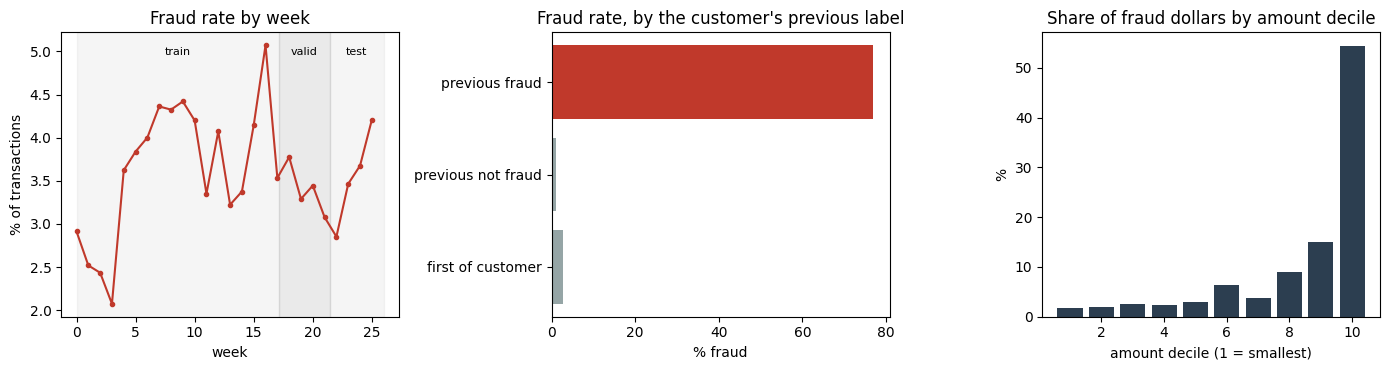

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
ax = axes[0]
ax.plot(weekly["week"], 100 * weekly["fraud_rate"], marker="o", ms=3, color="#c0392b")
for lo, hi, name in ((0, data.TRAIN_END, "train"), (data.TRAIN_END, data.VALID_END, "valid"),
                     (data.VALID_END, weekly["week"].max() * 7 + 7, "test")):
    ax.axvspan(lo / 7, hi / 7, alpha=0.08 if name != "valid" else 0.16, color="grey")
    ax.text((lo + hi) / 14, ax.get_ylim()[1] * 0.95 if ax.get_ylim()[1] else 1, name, ha="center", fontsize=8)
ax.set(title="Fraud rate by week", xlabel="week", ylabel="% of transactions")
ax = axes[1]
order = ["first transaction of customer", "previous transaction not fraud", "previous transaction fraud"]
p = propagation.reindex(order)
ax.barh(["first of customer", "previous not fraud", "previous fraud"], 100 * p["fraud_rate"], color=["#95a5a6", "#95a5a6", "#c0392b"])
ax.set(title="Fraud rate, by the customer's previous label", xlabel="% fraud")
ax = axes[2]
ax.bar(amount["decile"], 100 * amount["share_of_fraud_dollars"], color="#2c3e50")
ax.set(title="Share of fraud dollars by amount decile", xlabel="amount decile (1 = smallest)", ylabel="%")
fig.tight_layout()
data.savefig(fig, "01_audit", SOURCE)

## Record and verdict

In [11]:
o = overview.set_index("split")
p = propagation["fraud_rate"]
record = {
    "shape": {"transactions": int(o.loc["all", "transactions"]), "frauds": int(o.loc["all", "frauds"]),
              "fraud_rate": float(o.loc["all", "fraud_rate"]), "days": int(o.loc["all", "last_day"]) + 1,
              "identity_share": float(o.loc["all", "identity_share"]),
              "fraud_dollar_share": float(o.loc["all", "fraud_dollar_share"])},
    "splits": {s: {"transactions": int(o.loc[s, "transactions"]), "frauds": int(o.loc[s, "frauds"]),
                   "fraud_rate": float(o.loc[s, "fraud_rate"]), "days": [int(o.loc[s, "first_day"]), int(o.loc[s, "last_day"])]}
               for s in ("train", "valid", "test")},
    "weekly_fraud_rate": {"min": float(weekly["fraud_rate"].min()), "max": float(weekly["fraud_rate"].max()),
                          "weeks": int(len(weekly))},
    "segments": segments.to_dict(orient="records"),
    "missingness": {"families": family.reset_index(names="family").to_dict(orient="records"),
                    "v_blocks": int(len(v_blocks)), "v_blocks_same_rows": int(sum(same_rows))},
    "customers": {k: float(v) for k, v in customers.iloc[0].items()},
    "label_propagation": {k: {"transactions": int(r["transactions"]), "fraud_rate": float(r["fraud_rate"])}
                          for k, r in propagation.iterrows()},
    "leakage": {k: {"frauds": int(r["frauds"]), "recall": float(r["recall"]), "precision": float(r["precision"])}
                for k, r in leak.iterrows()},
    "amount_deciles": amount[["decile", "min_amount", "max_amount", "fraud_rate", "share_of_fraud_dollars"]].to_dict(orient="records"),
}
write_metrics("01_audit", record, SOURCE)

In [12]:
sh, lp, lk = record["shape"], record["label_propagation"], record["leakage"]
id_rate = segments[segments["dimension"] == "identity"].set_index("level")["fraud_rate"]
ratio = lp["previous transaction fraud"]["fraud_rate"] / max(lp["previous transaction not fraud"]["fraud_rate"], 1e-9)
show_verdict(
    "Verdict: phase 1, audit",
    [
        f"**{sh['transactions']:,} transactions over {sh['days']} days, {sh['fraud_rate']:.2%} fraud** "
        f"({sh['fraud_dollar_share']:.1%} of dollars); weekly fraud rate between {record['weekly_fraud_rate']['min']:.1%} and "
        f"{record['weekly_fraud_rate']['max']:.1%}. Each split holds enough fraud to measure: "
        + ", ".join(f"{s} {v['frauds']:,}" for s, v in record["splits"].items()) + ".",
        f"**The label is largely a property of the customer.** When an approximate customer's previous transaction is "
        f"labelled fraud, the next one is fraud {lp['previous transaction fraud']['fraud_rate']:.0%} of the time, against "
        f"{lp['previous transaction not fraud']['fraud_rate']:.1%} otherwise ({ratio:.0f}×).",
        f"**So a random split would leak.** Recognizing customers already labelled fraud finds "
        f"{lk['random 20% hold-out']['recall']:.0%} of the fraud in a random hold-out, but {lk['test']['recall']:.0%} in the "
        "later test months, where only the past is known. Validation is by time, and phase 3 reports how much of the model's "
        "skill comes from returning customers.",
        f"**The {len(miss['V'])} provider `V` columns form {record['missingness']['v_blocks']} blocks** by missing rate "
        f"({record['missingness']['v_blocks_same_rows']} missing on identical rows). Device data exists for "
        f"{sh['identity_share']:.0%} of transactions; fraud rate {id_rate['device data']:.1%} with it, "
        f"{id_rate['no device data']:.1%} without.",
    ],
    "Phase 2 builds features from each customer's earlier transactions only, and tests that none can see the future.",
)

### Verdict: phase 1, audit

1. **590,540 transactions over 182 days, 3.50% fraud** (3.9% of dollars); weekly fraud rate between 2.1% and 5.1%. Each split holds enough fraud to measure: train 14,600, valid 2,850, test 3,213.
2. **The label is largely a property of the customer.** When an approximate customer's previous transaction is labelled fraud, the next one is fraud 77% of the time, against 1.0% otherwise (80×).
3. **So a random split would leak.** Recognizing customers already labelled fraud finds 74% of the fraud in a random hold-out, but 16% in the later test months, where only the past is known. Validation is by time, and phase 3 reports how much of the model's skill comes from returning customers.
4. **The 339 provider `V` columns form 15 blocks** by missing rate (15 missing on identical rows). Device data exists for 24% of transactions; fraud rate 7.8% with it, 2.1% without.

**Next:** Phase 2 builds features from each customer's earlier transactions only, and tests that none can see the future.